# 03 - Módulo 2: Pronóstico de casos de dengue (RNN / LSTM)

**Proyecto 2: VectorIA** - Colegio Universitario de Cartago (CUC)

Objetivo: predecir los casos de dengue de las próximas 4 semanas usando las últimas 26 semanas de casos, clima (lluvia, temperatura y humedad) y fecha.

Seguimos los mismos pasos del ejercicio de clase RNN-Forecast, con los cambios que pide el proyecto:
- Varias variables de entrada en lugar de una.
- Se predicen 4 semanas a la vez (Dense de 4 neuronas).
- Se compara un modelo base SimpleRNN contra el LSTM, y los dos contra el baseline estacional (misma semana del año anterior).
- Al final se pronostican 2025 y 2026, repitiendo el pronóstico como en el forecast de clase.

# 1.Importación librerías

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' # Oculta los mensajes internos de TensorFlow

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')

# 2.Importación fuente de datos

In [2]:
# Usamos los datos procesados en el EDA (01_EDA.ipynb), con la fecha como índice
df = pd.read_csv('../data/processed/dengue_nacional_procesado.csv', index_col='fecha_inicio_semana', parse_dates=True)

In [3]:
df.head()

,anio,semana_epi,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct,mes,log_casos,log_lluvia,lluvia_4sem,baseline_estacional,temp_min_c_lag6,temp_min_c_lag8,log_lluvia_lag3,log_lluvia_lag4,humedad_rel_pct_lag1,humedad_rel_pct_lag2
fecha_inicio_semana,,,,,,,,,,,,,,,,,,,
2013-12-29,2014,1,239,4.62,11.0,27.2,19.9,84.9,12,5.476464,2.484907,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-01-05,2014,2,257,4.97,8.9,27.0,19.7,83.8,1,5.549076,2.292535,NaN,NaN,NaN,NaN,NaN,NaN,84.9,NaN
2014-01-12,2014,3,184,3.56,4.5,27.1,19.5,81.7,1,5.214936,1.704748,NaN,NaN,NaN,NaN,NaN,NaN,83.8,84.9
2014-01-19,2014,4,156,3.02,7.7,27.1,19.5,80.0,1,5.049856,2.163323,32.1,NaN,NaN,NaN,2.484907,NaN,81.7,83.8
2014-01-26,2014,5,189,3.66,4.7,27.2,18.7,78.0,1,5.241747,1.740466,25.8,NaN,NaN,NaN,2.292535,2.484907,80.0,81.7


Cada fila es una semana, desde el 29 de diciembre de 2013 hasta el 22 de diciembre de 2024. Además de los casos y el clima, el archivo ya trae las columnas que creamos en el EDA, como log_casos y log_lluvia.

In [4]:
len(df)

574

# 3.Preprocesado

## 3.1Visualización de la secuencia

<Axes: xlabel='fecha_inicio_semana'>

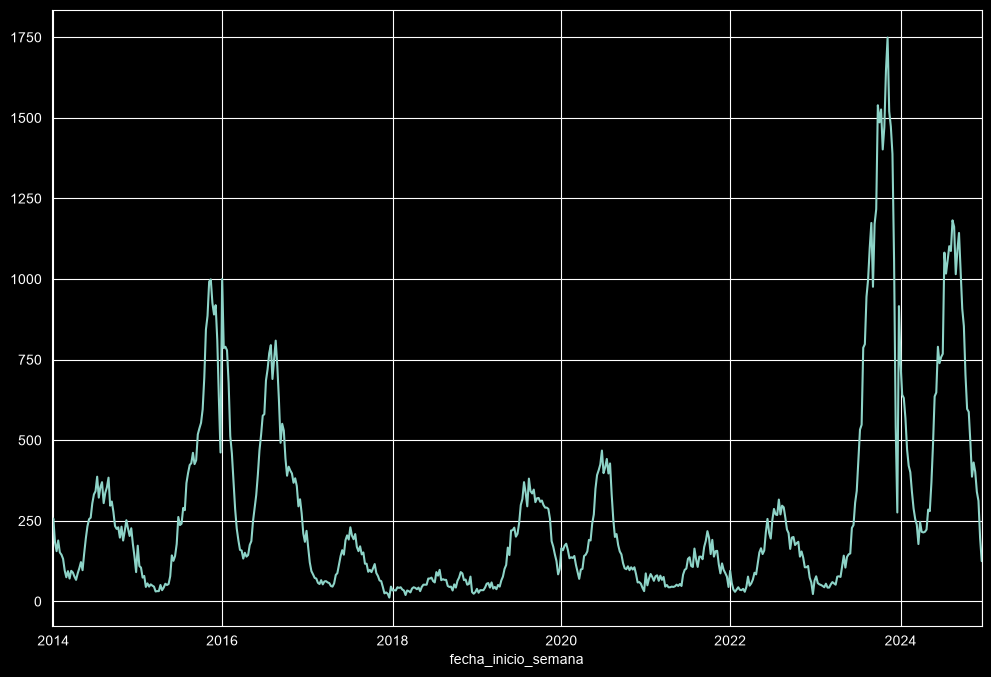

In [5]:
df['casos_dengue'].plot(figsize=(12,8))

<Axes: xlabel='fecha_inicio_semana'>

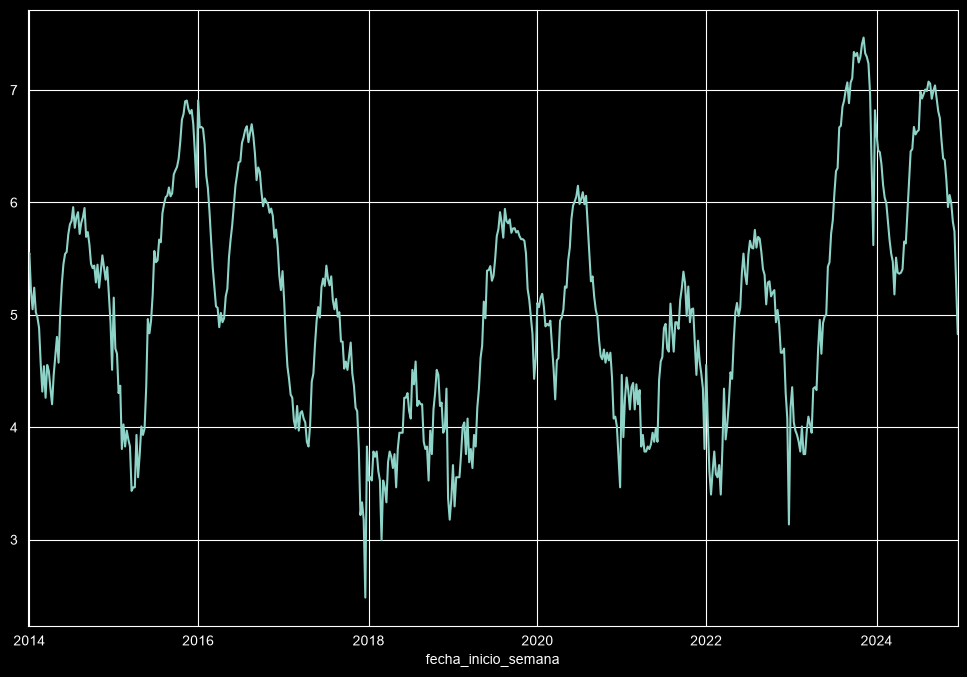

In [6]:
# En logaritmo los brotes ya no dominan la escala (decisión tomada en el EDA)
df['log_casos'].plot(figsize=(12,8))

### Interpretación
En el primer gráfico los brotes de 2023 y 2024 son tan altos que los años tranquilos casi no se ven. En logaritmo todos los años quedan en una escala parecida y se ve mejor el patrón que se repite cada año: los casos bajan a inicios de año y suben a mitad de año. Por eso el modelo trabaja con log_casos.

## 3.2 Variables de entrada
Usamos las variables que salieron mejor en el EDA: los casos pasados (log_casos), la temperatura mínima, la lluvia en logaritmo y la humedad. También la temperatura máxima, que la pide el proyecto.

La fecha la agregamos como seno y coseno de la semana del año. Así la semana 52 queda cerca de la semana 1, porque el año es un ciclo.

Los rezagos que encontramos en el EDA (temperatura mínima de 6 a 9 semanas, lluvia de 3 a 4 y humedad de 1 a 2) quedan dentro de la ventana de 26 semanas que ve el modelo, así que no hace falta crearlos como columnas aparte.

In [7]:
df['semana_sin'] = np.sin(2*np.pi*df['semana_epi']/52)
df['semana_cos'] = np.cos(2*np.pi*df['semana_epi']/52)

In [8]:
# Nos quedamos con las columnas de entrada: casos, clima y fecha
columnas = ['log_casos', 'temp_min_c', 'log_lluvia', 'humedad_rel_pct', 'temp_max_c', 'semana_sin', 'semana_cos']
df[columnas].head()

,log_casos,temp_min_c,log_lluvia,humedad_rel_pct,temp_max_c,semana_sin,semana_cos
fecha_inicio_semana,,,,,,,
2013-12-29,5.476464,19.9,2.484907,84.9,27.2,0.120537,0.992709
2014-01-05,5.549076,19.7,2.292535,83.8,27.0,0.239316,0.970942
2014-01-12,5.214936,19.5,1.704748,81.7,27.1,0.354605,0.935016
2014-01-19,5.049856,19.5,2.163323,80.0,27.1,0.464723,0.885456
2014-01-26,5.241747,18.7,1.740466,78.0,27.2,0.568065,0.822984


## 3.3 Variable a predecir
En el EDA vimos que en 2023-2024 los casos llegan a 1749, pero en los años de entrenamiento el máximo es 1000. Si el modelo predice los casos directamente, nunca vio valores tan altos y se queda corto en los brotes.

Por eso el modelo predice cuánto cambian los casos respecto a la última semana conocida, en logaritmo:

cambio = log(casos de la semana futura) - log(casos de la última semana)

Un cambio de 0 es que se mantienen igual, 0.69 es que se duplican y -0.69 que bajan a la mitad. Después lo pasamos otra vez a número de casos.

In [9]:
semanas_pred = 4 # Número de semanas a predecir

# cambio_k: log(casos) de la semana k menos log(casos) de la última semana conocida
for k in range(semanas_pred):
    df[f'cambio_{k+1}'] = df['log_casos'].shift(-k) - df['log_casos'].shift(1)

columnas_objetivo = ['cambio_1', 'cambio_2', 'cambio_3', 'cambio_4']

In [10]:
# Ejemplo: inicio del brote de 2023, los cambios son positivos porque los casos van subiendo
df[['casos_dengue'] + columnas_objetivo].loc['2023-07-02':'2023-08-06']

,casos_dengue,cambio_1,cambio_2,cambio_3,cambio_4
fecha_inicio_semana,,,,,
2023-07-02,343,0.114145,0.354057,0.554936,0.582690
2023-07-09,436,0.239912,0.440791,0.468545,0.830498
2023-07-16,533,0.200879,0.228633,0.590586,0.604466
2023-07-23,548,0.027754,0.389707,0.403587,0.572664
2023-07-30,787,0.361953,0.375833,0.544910,0.600479
2023-08-06,798,0.013880,0.182957,0.238527,0.332106


# 4.Train Test Split

In [11]:
len(df)

574

In [12]:
# El dataset es semanal (574 semanas = 11 años). Test: 2023-2024 (104 semanas). Validación: 2022 (52 semanas)
tamaño_test = 104
tamaño_val = 52

In [13]:
test_ind = len(df) - tamaño_test
val_ind = test_ind - tamaño_val

In [14]:
val_ind, test_ind

(418, 470)

In [15]:
train = df.iloc[:val_ind]
val = df.iloc[val_ind:test_ind]
test = df.iloc[test_ind:]

In [16]:
print('Train:', train.index.min().date(), 'a', train.index.max().date())
print('Validación:', val.index.min().date(), 'a', val.index.max().date())
print('Test:', test.index.min().date(), 'a', test.index.max().date())

Train: 2013-12-29 a 2021-12-26
Validación: 2022-01-02 a 2022-12-25
Test: 2023-01-01 a 2024-12-22


Train tiene 418 semanas (2014-2021), validación 52 semanas (2022) y test 104 semanas (2023-2024). No se puede dividir al azar como en otros problemas, porque el modelo estaría viendo semanas del futuro para predecir el pasado.

NOTA: en el ejercicio de clase el conjunto de test se usó también como validación para el EarlyStopping. Aquí separamos 2022 como validación, para que el test (2023-2024) no se use en ninguna decisión del entrenamiento y la evaluación final sea más justa.

# 5.Escalado

In [17]:
from sklearn.preprocessing import MinMaxScaler

In [18]:
scaler = MinMaxScaler()   # Para las variables de entrada
scaler_y = MinMaxScaler() # Para la variable a predecir

In [19]:
# Solo utilizamos train data para el ajuste del escalado, sino estaríamos asumiendo información acerca del conjunto de test
scaler.fit(train[columnas])

# Las últimas 3 semanas de train no se usan porque su cambio usa semanas de validación
scaler_y.fit(train[columnas_objetivo].iloc[:-(semanas_pred-1)])

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](4,)","[1.34,1.04,1.07,1.04]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](4,)","[-0.98,-1.17,-0.98,-1.32]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](4,)","[2.32,2.21,2.05,2.36]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['cambio_1','cambio_2','cambio_3','cambio_4']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](4,)","[0.42,0.53,0.48,0.56]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,415


In [20]:
# Escalamos toda la serie con los escaladores ajustados en train
# (las ventanas de validación y test necesitan las 26 semanas anteriores)
scaled_data = scaler.transform(df[columnas])
scaled_y = scaler_y.transform(df[columnas_objetivo])

In [21]:
scaled_data[:val_ind].min(), scaled_data[:val_ind].max()

(np.float64(0.0), np.float64(1.0))

In [22]:
# En test hay valores un poco mayores a 1 por los brotes de 2023-2024 y el clima de esos años
scaled_data[test_ind:].max()

np.float64(1.1263991248414769)

### Interpretación
El MinMaxScaler deja cada variable entre 0 y 1, porque las redes aprenden mejor cuando todas las variables tienen la misma escala (si no, los casos pesarían mucho más que la humedad). En train todo queda entre 0 y 1. En test el máximo pasa un poco de 1 porque hubo brotes más grandes que en train. Para las entradas eso no es problema; por eso la variable a predecir es el cambio de casos y no los casos (sección 3.3).

Usamos dos escaladores: uno para las 7 variables de entrada y otro para las 4 columnas a predecir, para poder desescalar las predicciones después con inverse_transform.

# 6. Creación Generador Serie Temporal

In [23]:
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

In [24]:
# Cogemos una ventana de 26 semanas atrás para predecir las 4 semanas siguientes
longitud = 26
tamaño_batch = 16
n_variables = len(columnas) # Hay múltiples variables, cogemos el número de columnas

In [25]:
# start_index y end_index limitan cada generador a su periodo (las 4 semanas a predecir quedan dentro de él)
generador = TimeseriesGenerator(data=scaled_data, targets=scaled_y, length=longitud, batch_size=tamaño_batch,
                                start_index=0, end_index=val_ind-semanas_pred)

val_generador = TimeseriesGenerator(data=scaled_data, targets=scaled_y, length=longitud, batch_size=tamaño_batch,
                                    start_index=val_ind-longitud, end_index=test_ind-semanas_pred)

test_generador = TimeseriesGenerator(data=scaled_data, targets=scaled_y, length=longitud, batch_size=1,
                                     start_index=test_ind-longitud, end_index=len(df)-semanas_pred)

In [26]:
# ¿Qué obtenemos del primer batch? (16 ventanas de 26 semanas con 7 variables)
X,y = generador[0]
X.shape, y.shape

((16, 26, 7), (16, 4))

In [27]:
print(f'Dado el array de entrada (log_casos escalado de las 26 semanas): \n{X[0][:,0].round(2)}')
print(f'Predecimos (cambio escalado de las 4 semanas siguientes): \n {y[0].round(2)}')

Dado el array de entrada (log_casos escalado de las 26 semanas): 
[0.68 0.69 0.62 0.58 0.62 0.57 0.56 0.54 0.47 0.41 0.47 0.4  0.47 0.46
 0.42 0.39 0.45 0.49 0.52 0.47 0.57 0.63 0.67 0.69 0.7  0.73]
Predecimos (cambio escalado de las 4 semanas siguientes): 
 [0.46 0.58 0.59 0.58]


### Interpretación
El generador corta la serie en ventanas: cada ejemplo tiene 26 semanas seguidas con las 7 variables (X) y el cambio de las 4 semanas siguientes (y). Cada batch tiene 16 ejemplos, por eso X tiene forma (16, 26, 7) y y tiene forma (16, 4).

Con start_index y end_index cada generador usa solo su periodo: train predice semanas de 2014-2021, validación semanas de 2022 y test semanas de 2023-2024. El generador de test usa batch_size=1, igual que en clase.

# 7.Creación del modelo

In [28]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import SimpleRNN
from tensorflow.keras.layers import Dropout

## 7.1 Modelo base: SimpleRNN

In [29]:
tf.keras.utils.set_random_seed(42) # Para que los resultados se puedan repetir

model_rnn = Sequential()
model_rnn.add(SimpleRNN(32, activation='relu', input_shape=(longitud, n_variables)))
model_rnn.add(Dense(semanas_pred)) # 4 neuronas de salida, una por cada semana a predecir
model_rnn.compile(optimizer='adam', loss='mse')

In [30]:
model_rnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,412 (5.52 KB)

 Trainable params: 1,412 (5.52 KB)

 Non-trainable params: 0 (0.00 B)

La SimpleRNN es la red recurrente más simple: lee las 26 semanas una por una y va pasando lo que aprende a la siguiente. Tiene 32 neuronas recurrentes y una capa Dense de 4 neuronas, una por cada semana a predecir. Tiene pocos parámetros (1,412), por eso es el modelo base.

## 7.2 Modelo principal: LSTM

In [31]:
tf.keras.utils.set_random_seed(42)

model = Sequential()
model.add(LSTM(64, activation='relu', return_sequences=True, input_shape=(longitud, n_variables))) # return_sequences=True para pasarle las 26 semanas a la siguiente LSTM
model.add(LSTM(32, activation='relu'))
model.add(Dropout(0.2)) # Apaga el 20% de las neuronas al entrenar para reducir el sobreajuste
model.add(Dense(semanas_pred))
model.compile(optimizer='adam', loss='mse')

In [32]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 26, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,980 (121.02 KB)

 Trainable params: 30,980 (121.02 KB)

 Non-trainable params: 0 (0.00 B)

Capas del LSTM (la arquitectura que pide el proyecto):
- LSTM de 64 neuronas: a diferencia de la SimpleRNN, tiene "memoria" (celdas y compuertas) que decide qué información de semanas anteriores guardar y cuál olvidar. Usa return_sequences=True para pasarle las 26 semanas completas a la siguiente capa.
- LSTM de 32 neuronas: resume la secuencia en un solo vector.
- Dropout(0.2): durante el entrenamiento apaga al azar el 20% de las neuronas para que el modelo no se aprenda de memoria los datos.
- Dense(4): la salida, una neurona por cada una de las 4 semanas.

Como en clase usamos activation='relu', optimizador adam y pérdida mse (error cuadrático medio).

# 8. Entrenamiento del modelo

NOTA: en clase se usó model.fit_generator(), que ya no existe en TensorFlow 2.21. Ahora model.fit() recibe el generador de la misma forma.

Usamos más paciencia que en clase (15 épocas) porque la validación de 2022 sube y baja un poco, y restore_best_weights=True para quedarnos con los pesos de la mejor época.

In [33]:
from tensorflow.keras.callbacks import EarlyStopping

In [34]:
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

## 8.1 SimpleRNN

In [35]:
model_rnn.fit(generador, epochs=300,
              validation_data=val_generador,
              callbacks=[early_stop], verbose=2)

Epoch 1/300
25/25 - 2s - 62ms/step - loss: 0.2694 - val_loss: 0.1324
Epoch 2/300
25/25 - 0s - 6ms/step - loss: 0.0758 - val_loss: 0.0450
Epoch 3/300
25/25 - 0s - 5ms/step - loss: 0.0365 - val_loss: 0.0314
Epoch 4/300
25/25 - 0s - 5ms/step - loss: 0.0299 - val_loss: 0.0277
Epoch 5/300
25/25 - 0s - 5ms/step - loss: 0.0274 - val_loss: 0.0242
Epoch 6/300
25/25 - 0s - 6ms/step - loss: 0.0263 - val_loss: 0.0246
Epoch 7/300
25/25 - 0s - 5ms/step - loss: 0.0251 - val_loss: 0.0244
Epoch 8/300
25/25 - 0s - 5ms/step - loss: 0.0241 - val_loss: 0.0219
Epoch 9/300
25/25 - 0s - 5ms/step - loss: 0.0240 - val_loss: 0.0210
Epoch 10/300
25/25 - 0s - 6ms/step - loss: 0.0235 - val_loss: 0.0211
Epoch 11/300
25/25 - 0s - 5ms/step - loss: 0.0220 - val_loss: 0.0198
Epoch 12/300
25/25 - 0s - 5ms/step - loss: 0.0210 - val_loss: 0.0197
Epoch 13/300
25/25 - 0s - 5ms/step - loss: 0.0208 - val_loss: 0.0196
Epoch 14/300
25/25 - 0s - 6ms/step - loss: 0.0203 - val_loss: 0.0199
Epoch 15/300
25/25 - 0s - 5ms/step - loss:

In [36]:
losses_rnn = pd.DataFrame(model_rnn.history.history)

<Axes: >

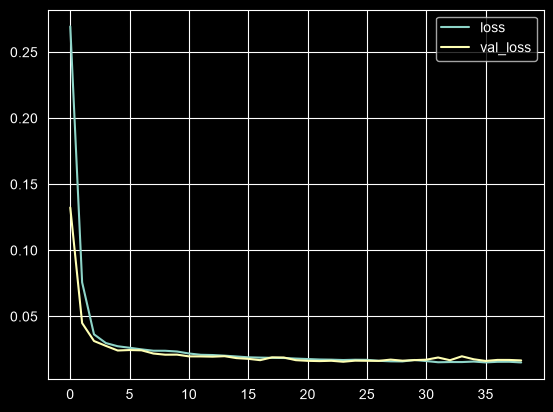

In [37]:
losses_rnn.plot()

loss es el error en train y val_loss el error en validación, por época. La SimpleRNN se detuvo cuando val_loss dejó de mejorar durante 15 épocas.

## 8.2 LSTM

In [38]:
model.fit(generador, epochs=300,
          validation_data=val_generador,
          callbacks=[early_stop], verbose=2)

Epoch 1/300
25/25 - 2s - 99ms/step - loss: 0.0940 - val_loss: 0.0398
Epoch 2/300
25/25 - 0s - 12ms/step - loss: 0.0347 - val_loss: 0.0193
Epoch 3/300
25/25 - 0s - 12ms/step - loss: 0.0323 - val_loss: 0.0182
Epoch 4/300
25/25 - 0s - 12ms/step - loss: 0.0288 - val_loss: 0.0173
Epoch 5/300
25/25 - 0s - 13ms/step - loss: 0.0279 - val_loss: 0.0178
Epoch 6/300
25/25 - 0s - 12ms/step - loss: 0.0261 - val_loss: 0.0178
Epoch 7/300
25/25 - 0s - 12ms/step - loss: 0.0262 - val_loss: 0.0186
Epoch 8/300
25/25 - 0s - 13ms/step - loss: 0.0260 - val_loss: 0.0177
Epoch 9/300
25/25 - 0s - 12ms/step - loss: 0.0237 - val_loss: 0.0169
Epoch 10/300
25/25 - 0s - 14ms/step - loss: 0.0228 - val_loss: 0.0154
Epoch 11/300
25/25 - 0s - 12ms/step - loss: 0.0255 - val_loss: 0.0190
Epoch 12/300
25/25 - 0s - 12ms/step - loss: 0.0241 - val_loss: 0.0174
Epoch 13/300
25/25 - 0s - 13ms/step - loss: 0.0236 - val_loss: 0.0167
Epoch 14/300
25/25 - 0s - 13ms/step - loss: 0.0225 - val_loss: 0.0153
Epoch 15/300
25/25 - 0s - 12m

In [39]:
losses = pd.DataFrame(model.history.history)

<Axes: >

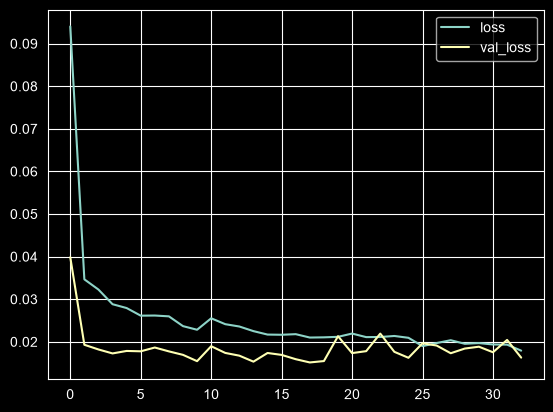

In [40]:
losses.plot()

### Interpretación
La pérdida baja rápido en las primeras épocas y después se estabiliza. Cuando val_loss deja de mejorar, el EarlyStopping detiene el entrenamiento para que el modelo no se aprenda de memoria los datos de train. La pérdida de validación queda más baja que la de train porque 2022 fue un año tranquilo, mientras que train incluye los brotes de 2015 y 2016.

# 9. Evaluación del modelo

## 9.1 Predicción sobre el conjunto de Test

In [41]:
test_predictions = model.predict(test_generador)

101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [42]:
test_predictions.shape # 101 ventanas de test, cada una con 4 semanas

(101, 4)

In [43]:
# Desescalamos las predicciones para obtener el cambio real ("true_predictions")
true_predictions = scaler_y.inverse_transform(test_predictions)

In [44]:
# Pasamos de cambio a número de casos: casos = exp(log(casos de la última semana) + cambio)
filas = np.arange(test_ind, len(df)-semanas_pred+1) # Primera semana que predice cada ventana
ultimo_log = df['log_casos'].values[filas-1].reshape(-1,1)

casos_pred = np.exp(ultimo_log + true_predictions)

In [45]:
# Predicción de la semana siguiente (semana 1) comparada con los casos reales
test = test.iloc[:len(filas)][['casos_dengue']].copy()
test['Predicción'] = casos_pred[:,0].round()

In [46]:
test

,casos_dengue,Predicción
fecha_inicio_semana,,
2023-01-01,65,22.0
2023-01-08,78,62.0
2023-01-15,57,75.0
2023-01-22,53,55.0
2023-01-29,51,51.0
...,...,...
2024-11-03,494,583.0
2024-11-10,387,487.0
2024-11-17,431,380.0


<Axes: xlabel='fecha_inicio_semana'>

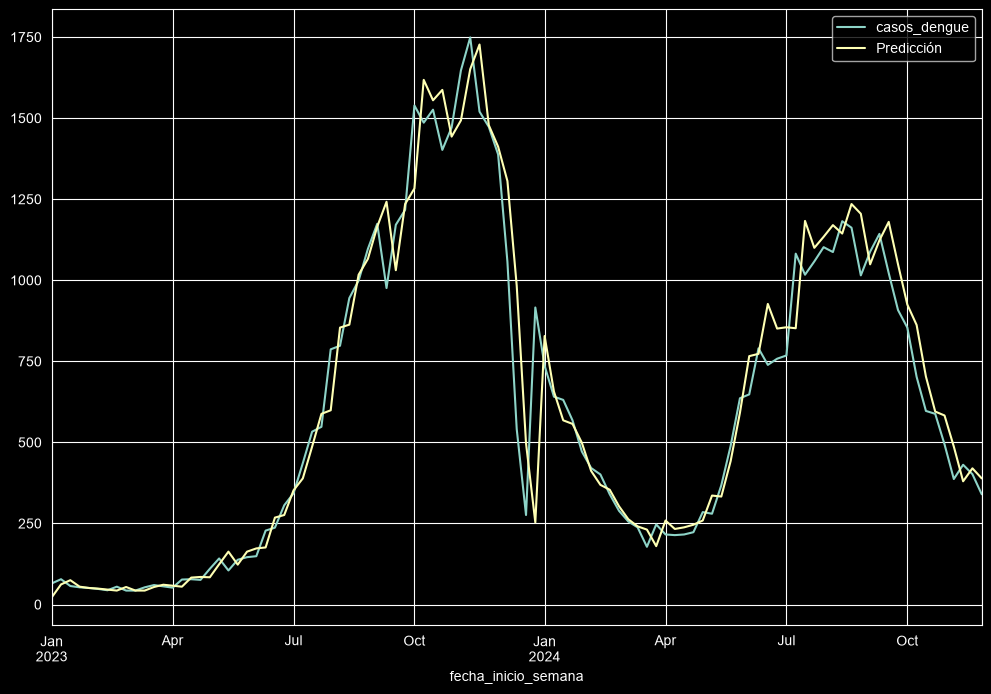

In [47]:
test.plot(figsize=(12,8))

In [48]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [49]:
# RMSE de la semana 1
np.sqrt(mean_squared_error(test['casos_dengue'],test['Predicción']))

np.float64(119.55884254911122)

### Interpretación
La predicción de la semana siguiente sigue muy de cerca a los casos reales, incluso en los brotes de 2023 y 2024. El RMSE indica que, en la semana 1, el modelo se equivoca en unos 120 casos en promedio (el RMSE castiga más los errores grandes). Las primeras semanas de enero de 2023 tienen un error alto porque la última semana conocida es de fin de año, con subregistro.

### Comparación con la SimpleRNN y el baseline estacional
Medimos las 4 semanas de cada ventana. Además del RMSE y el MAE calculamos una precisión del pronóstico: 100 x (1 - suma de errores / suma de casos reales), que es el porcentaje de casos que se acierta en promedio.

In [50]:
# Casos reales de las 4 semanas de cada ventana
casos_reales = np.column_stack([df['casos_dengue'].values[filas+k] for k in range(semanas_pred)])

# Baseline estacional: los casos de la misma semana del año anterior (52 semanas antes)
baseline = np.column_stack([df['casos_dengue'].values[filas+k-52] for k in range(semanas_pred)])

# Predicciones de la SimpleRNN (mismos pasos que con el LSTM)
pred_rnn = np.exp(ultimo_log + scaler_y.inverse_transform(model_rnn.predict(test_generador)))

101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [51]:
def metricas(real, pred):
    rmse = np.sqrt(mean_squared_error(real.ravel(), pred.ravel()))
    mae = mean_absolute_error(real.ravel(), pred.ravel())
    precision = 100 * (1 - np.abs(real - pred).sum() / real.sum())
    return round(rmse, 1), round(mae, 1), round(precision, 1)

In [52]:
resultados = pd.DataFrame([metricas(casos_reales, baseline),
                           metricas(casos_reales, pred_rnn),
                           metricas(casos_reales, casos_pred)],
                          index=['Baseline estacional', 'SimpleRNN', 'LSTM'],
                          columns=['RMSE', 'MAE', 'Precisión (%)'])
resultados

,RMSE,MAE,Precisión (%)
Baseline estacional,638.3,455.7,25.2
SimpleRNN,231.3,144.0,76.4
LSTM,173.4,105.8,82.6


In [53]:
# Error del LSTM según cuántas semanas hacia adelante se predice
por_semana = pd.DataFrame([metricas(casos_reales[:,k], casos_pred[:,k]) for k in range(semanas_pred)],
                          index=['Semana 1', 'Semana 2', 'Semana 3', 'Semana 4'],
                          columns=['RMSE', 'MAE', 'Precisión (%)'])
por_semana

,RMSE,MAE,Precisión (%)
Semana 1,119.6,71.0,88.3
Semana 2,162.1,97.9,83.9
Semana 3,190.1,117.3,80.8
Semana 4,208.7,137.2,77.5


Mientras más lejos se predice, más difícil es: la semana 1 tiene una precisión cercana al 88% y la semana 4 cercana al 77%. Esto es normal en cualquier pronóstico, porque entre más tiempo pasa, más cosas pueden cambiar.

<Axes: xlabel='fecha_inicio_semana'>

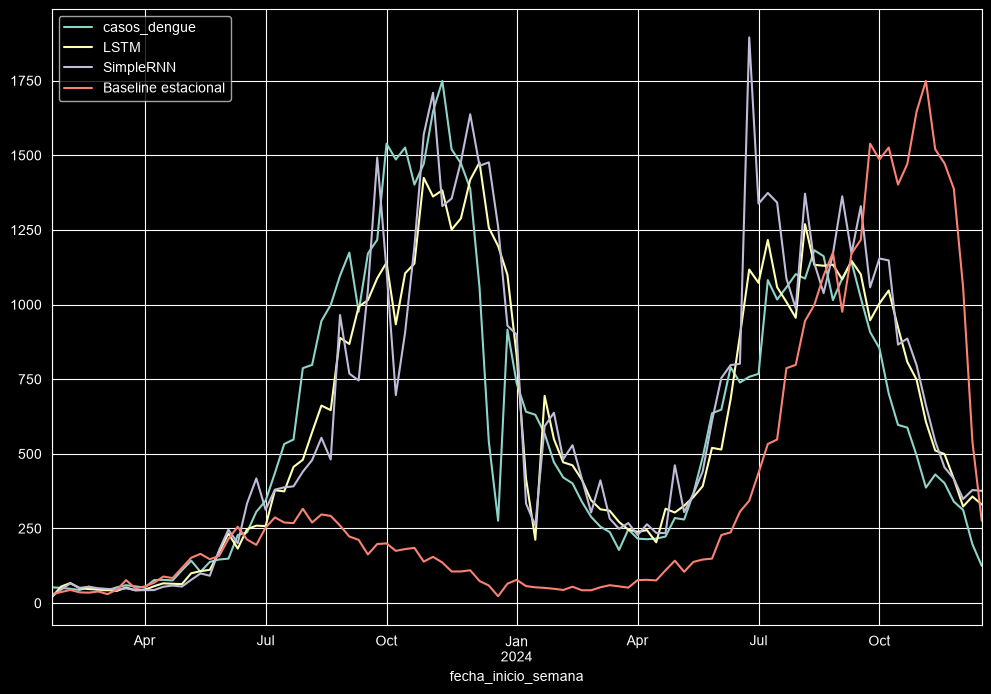

In [54]:
# Predicción a 4 semanas de los dos modelos y el baseline
pred_4 = pd.DataFrame({'casos_dengue': casos_reales[:,3],
                       'LSTM': casos_pred[:,3],
                       'SimpleRNN': pred_rnn[:,3],
                       'Baseline estacional': baseline[:,3]},
                      index=df.index[filas+3])
pred_4.plot(figsize=(12,8))

### Interpretación
- El LSTM tiene mucho menos error que el baseline estacional, que es la meta del proyecto. El baseline falla porque copia el año anterior: 2022 fue tranquilo y 2023 fue de brote, y en 2024 el brote llegó semanas antes que en 2023, así que el baseline queda desfasado.
- El LSTM también le gana a la SimpleRNN. La SimpleRNN es más inestable y en algunas semanas exagera los picos, porque le cuesta recordar información de muchas semanas atrás. El LSTM tiene memoria para eso.
- El error sube mientras más lejos se predice: la semana 1 es la que mejor sale y la semana 4 la que peor.
- A 4 semanas, el LSTM detecta cuándo los casos empiezan a subir, pero se queda un poco corto al inicio de los brotes.
- Los errores más grandes están en el cambio de año, por el subregistro de fin de año que encontramos en el EDA. En diciembre se reportan menos casos y se acumulan en enero, y eso no lo puede anticipar ningún modelo.

## 9.2 Predicción de nuevos datos (forecast)

In [55]:
# Cogemos todos los datos originales y escalamos en base a ellos
full_scaler = MinMaxScaler()
full_scaler_y = MinMaxScaler()
scaled_full_data = full_scaler.fit_transform(df[columnas])
scaled_full_y = full_scaler_y.fit_transform(df[columnas_objetivo])

In [56]:
generador = TimeseriesGenerator(scaled_full_data, scaled_full_y, length=longitud, batch_size=tamaño_batch,
                                end_index=len(df)-semanas_pred)

In [57]:
tf.keras.utils.set_random_seed(42)

model = Sequential()
model.add(LSTM(64, activation='relu', return_sequences=True, input_shape=(longitud, n_variables)))
model.add(LSTM(32, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(semanas_pred))
model.compile(optimizer='adam', loss='mse')

# Ajustamos el modelo, escogemos el número de epochs en base al entrenamiento anterior (no tiene sentido EarlyStopping puesto que no tenemos ahora datos de validación con los que comparar)
epocas = losses['val_loss'].idxmin() + 1
model.fit(generador, epochs=epocas, verbose=2)

Epoch 1/18
35/35 - 2s - 68ms/step - loss: 0.0827
Epoch 2/18
35/35 - 0s - 10ms/step - loss: 0.0323
Epoch 3/18
35/35 - 0s - 10ms/step - loss: 0.0287
Epoch 4/18
35/35 - 0s - 11ms/step - loss: 0.0243
Epoch 5/18
35/35 - 0s - 10ms/step - loss: 0.0243
Epoch 6/18
35/35 - 0s - 10ms/step - loss: 0.0227
Epoch 7/18
35/35 - 0s - 10ms/step - loss: 0.0230
Epoch 8/18
35/35 - 0s - 10ms/step - loss: 0.0218
Epoch 9/18
35/35 - 0s - 11ms/step - loss: 0.0199
Epoch 10/18
35/35 - 0s - 11ms/step - loss: 0.0202
Epoch 11/18
35/35 - 0s - 12ms/step - loss: 0.0206
Epoch 12/18
35/35 - 0s - 9ms/step - loss: 0.0189
Epoch 13/18
35/35 - 0s - 10ms/step - loss: 0.0193
Epoch 14/18
35/35 - 0s - 9ms/step - loss: 0.0189
Epoch 15/18
35/35 - 0s - 9ms/step - loss: 0.0190
Epoch 16/18
35/35 - 0s - 9ms/step - loss: 0.0187
Epoch 17/18
35/35 - 0s - 9ms/step - loss: 0.0166
Epoch 18/18
35/35 - 0s - 10ms/step - loss: 0.0177


In [58]:
# Última ventana de 26 semanas para predecir las 4 semanas siguientes
primer_batch = scaled_full_data[-longitud:]
batch_actual = primer_batch.reshape((1, longitud, n_variables))

forecast = full_scaler_y.inverse_transform(model.predict(batch_actual))[0]
forecast = np.exp(df['log_casos'].iloc[-1] + forecast) # De cambio a número de casos

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step


Creamos el nuevo índice de tiempos para el forecast

In [59]:
# Creamos el índice para que empiece en la semana siguiente a la última de nuestros datos (2024-12-22)
forecast_index = pd.date_range(start='2024-12-29', periods=semanas_pred, freq='7D')

In [60]:
forecast_df = pd.DataFrame(data=forecast.round(), index=forecast_index, columns=['Forecast'])

In [61]:
forecast_df

,Forecast
2024-12-29,110.0
2025-01-05,99.0
2025-01-12,85.0
2025-01-19,76.0


Estos son los casos que el modelo pronostica para las 4 semanas siguientes al último dato (diciembre 2024 - enero 2025). Siguen la tendencia a la baja que traían los casos al final de 2024.

(2819.0, 2875.0)

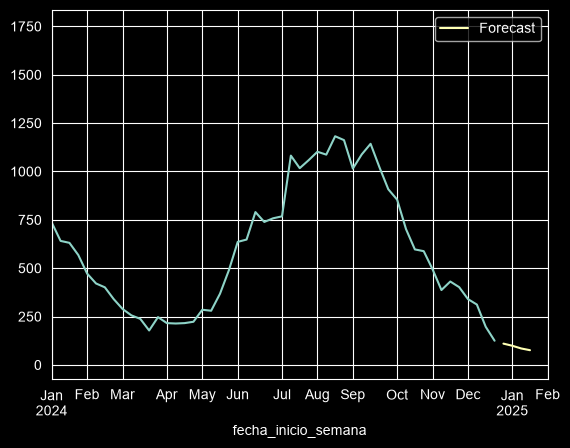

In [62]:
#Unimos ambos plots en la misma figura y hacemos zoom
ax = df['casos_dengue'].plot()
forecast_df.plot(ax=ax)
plt.xlim('2024-01-01','2025-02-01')

El forecast cae en las primeras semanas de 2025, justo después del fin de año. Como vimos en el EDA, en esas semanas hay un salto por el subregistro de diciembre, así que hay que tomarlo con cuidado.

In [63]:
model.save('../models/modelo_lstm_casos.h5')

In [64]:
import joblib

# La app también necesita los escaladores para preparar los datos y desescalar la predicción
joblib.dump({'scaler': full_scaler, 'scaler_y': full_scaler_y, 'columnas': columnas,
             'longitud': longitud, 'semanas_pred': semanas_pred},
            '../models/modelo_lstm_casos_escaladores.pkl')

['../models/modelo_lstm_casos_escaladores.pkl']

Se guardan dos archivos en la carpeta models: el modelo entrenado (.h5) y los escaladores (.pkl). La app necesita los dos: los escaladores para preparar las últimas 26 semanas igual que en el entrenamiento y para desescalar la predicción.

## 9.3 Pronóstico de 2025 y 2026
Los datos llegan hasta diciembre de 2024. Para pronosticar 2025 y 2026 hacemos lo mismo que en el ejercicio de clase de temperatura (forecast de 36 meses): el modelo predice 4 semanas, las agregamos a la ventana como si fueran datos, y volvemos a predecir. Lo repetimos 26 veces (26 x 4 = 104 semanas = 2 años).

Hay un problema: el modelo también necesita el clima de esas semanas, y no lo tenemos. Para cada semana futura usamos el clima promedio de esa misma semana del año en 2014-2024.

In [65]:
# Clima promedio de cada semana epidemiológica (2014-2024), para las semanas futuras
clima = ['temp_min_c', 'log_lluvia', 'humedad_rel_pct', 'temp_max_c']
clima_promedio = df.groupby('semana_epi')[clima].mean()
clima_promedio.head()

,temp_min_c,log_lluvia,humedad_rel_pct,temp_max_c
semana_epi,,,,
1,19.881818,2.299784,83.700000,27.136364
2,19.909091,2.481662,83.172727,26.945455
3,19.818182,1.975027,81.954545,27.245455
4,19.827273,1.869332,80.563636,27.527273
5,19.636364,1.967937,78.600000,27.763636


Para las semanas futuras también necesitamos la semana epidemiológica. Usamos la misma regla que traen los datos: las semanas empiezan en domingo y la semana 1 es la que contiene el 3 de enero.

In [66]:
def semana_epidemiologica(fecha):
    for anio in [fecha.year + 1, fecha.year, fecha.year - 1]:
        tres_enero = pd.Timestamp(anio, 1, 3)
        inicio = tres_enero - pd.Timedelta(days=(tres_enero.weekday() + 1) % 7) # Domingo de esa semana
        if fecha >= inicio:
            return anio, (fecha - inicio).days // 7 + 1

In [67]:
# Comprobamos que la regla da lo mismo que los datos en las 574 semanas
all(semana_epidemiologica(fecha) == (anio, semana)
    for fecha, anio, semana in zip(df.index, df['anio'], df['semana_epi']))

True

In [68]:
periodos = 26 # 26 bloques de 4 semanas = 104 semanas (2025 y 2026)

historia = df[columnas].copy() # Datos reales; aquí se van agregando las semanas pronosticadas
forecast_largo = []

for i in range(periodos):

    # Última ventana de 26 semanas (reales o ya pronosticadas)
    batch_actual = full_scaler.transform(historia.iloc[-longitud:]).reshape((1, longitud, n_variables))

    # Predecimos el cambio de las 4 semanas siguientes y lo desescalamos
    cambio = full_scaler_y.inverse_transform(model.predict(batch_actual, verbose=0))[0]
    ultimo_log = historia['log_casos'].iloc[-1]

    # Agregamos las 4 semanas nuevas a la historia (casos pronosticados + clima promedio)
    for k in range(semanas_pred):
        fecha = historia.index[-1] + pd.Timedelta(weeks=1)
        anio, semana = semana_epidemiologica(fecha)
        nueva = clima_promedio.loc[semana].copy()
        nueva['log_casos'] = ultimo_log + cambio[k]
        nueva['semana_sin'] = np.sin(2*np.pi*semana/52)
        nueva['semana_cos'] = np.cos(2*np.pi*semana/52)
        historia.loc[fecha] = nueva[columnas]
        forecast_largo.append([fecha, anio, semana, round(float(np.exp(nueva['log_casos'])))])

In [69]:
forecast_largo = pd.DataFrame(forecast_largo, columns=['fecha', 'anio', 'semana_epi', 'Forecast']).set_index('fecha')
forecast_largo.head(8)

,anio,semana_epi,Forecast
fecha,,,
2024-12-29,2025,1,110
2025-01-05,2025,2,99
2025-01-12,2025,3,85
2025-01-19,2025,4,76
2025-01-26,2025,5,68
2025-02-02,2025,6,62
2025-02-09,2025,7,55
2025-02-16,2025,8,51


Para tener una referencia, comparamos con un "año típico": la mediana de los casos de cada semana epidemiológica en 2014-2024.

In [70]:
# Año típico: mediana de los casos de cada semana epidemiológica (2014-2024)
mediana_semana = df.groupby('semana_epi')['casos_dengue'].median()
forecast_largo['Año típico'] = forecast_largo['semana_epi'].map(mediana_semana)

In [71]:
# Total de casos por año: pronóstico y año típico, comparado con los años reales
forecast_largo.groupby('anio')[['Forecast', 'Año típico']].sum()

,Forecast,Año típico
anio,,
2025,2836,9399.0
2026,1498,9399.0


In [72]:
df.groupby('anio')['casos_dengue'].sum()

anio
2014    11049
2015    17485
2016    23319
2017     5561
2018     2735
2019     9400
2020    10056
2021     5174
2022     7485
2023    30649
2024    31259
Name: casos_dengue, dtype: int64

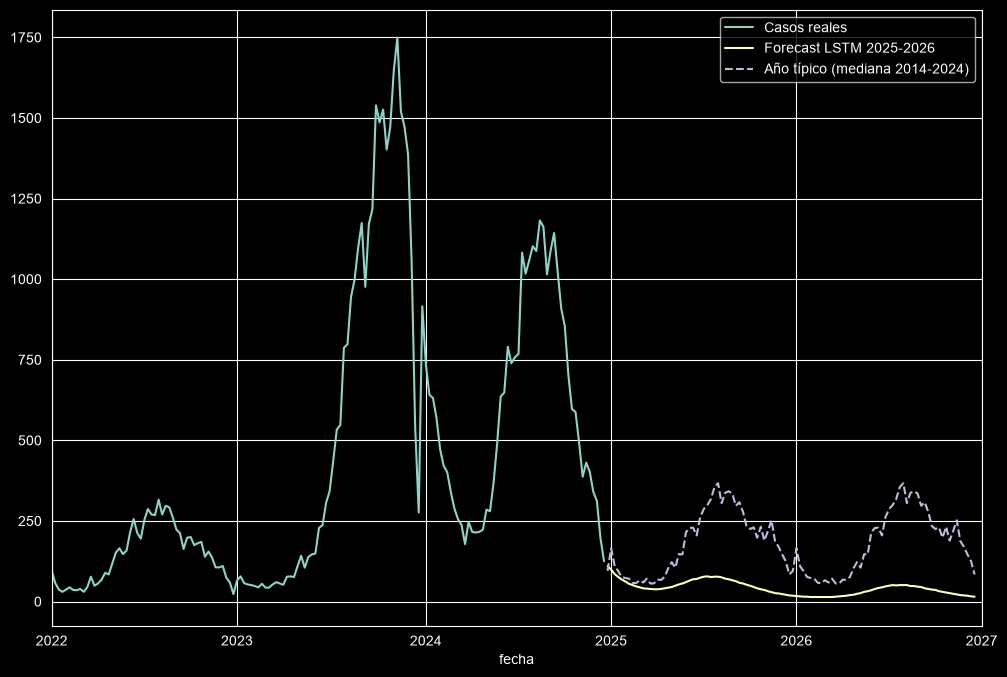

In [73]:
#Unimos los datos reales y el pronóstico de 2025-2026 en la misma figura
ax = df['casos_dengue'].plot(figsize=(12,8), label='Casos reales')
forecast_largo['Forecast'].plot(ax=ax, label='Forecast LSTM 2025-2026')
forecast_largo['Año típico'].plot(ax=ax, style='--', label='Año típico (mediana 2014-2024)')
plt.xlim('2022-01-01','2027-01-01')
plt.legend()

### Interpretación
- El pronóstico mantiene la forma de cada año: los casos bajan en los primeros meses y suben a mitad de año, igual que en los datos reales. Eso es lo que el modelo aprendió de la estacionalidad.
- El nivel va bajando: el modelo continúa la bajada que traían los casos al final de 2024, después del brote, y queda muy por debajo del año típico. En 2026 llega incluso a menos casos que el año más bajo de los datos (2018). Que los casos bajen después de un brote es normal (pasó después de 2016), pero tanto no es creíble.
- Este pronóstico tiene dos limitaciones importantes. Primero, cada bloque de 4 semanas usa predicciones anteriores como si fueran datos, así que el error se va acumulando. Segundo, el modelo no puede anticipar un brote nuevo, porque depende de cosas que no están en los datos (como el serotipo del virus o las campañas de control), y usa el clima promedio, no el real.
- Por eso el pronóstico de 2025-2026 sirve para ver la tendencia y la época de mayor riesgo, no como cifra exacta. En la sección 10 comprobamos qué tan confiable es un pronóstico a 2 años. El pronóstico confiable es el de 4 semanas (secciones 9.1 y 9.2), y cuando lleguen los datos reales de 2025-2026 se puede volver a entrenar el modelo con ellos.

# 10. Uso del modelo desde la clase PronosticadorDengue
Los mismos pasos de este notebook están organizados en la clase PronosticadorDengue (src/train/lstm.py), para usarlos desde la app de Streamlit. Comprobamos que la clase carga el modelo guardado y da el mismo forecast.

In [74]:
import sys
sys.path.append('..') # Para encontrar la carpeta src/

from src.train.lstm import PronosticadorDengue

In [75]:
datos = pd.read_csv('../data/processed/dengue_nacional_procesado.csv', parse_dates=['fecha_inicio_semana'])

pronosticador, modelo_cargado = PronosticadorDengue.cargar(datos, '../models')
pronosticador.pronosticar_futuro(modelo_cargado)

,Forecast
2024-12-29,110.0
2025-01-05,99.0
2025-01-12,85.0
2025-01-19,76.0


Para el dashboard, el usuario elige una semana y la clase pronostica las 4 semanas siguientes. Si la semana es de 2014-2024, también muestra los casos reales para comparar. Si es de 2025 o 2026, usa el pronóstico de la sección 9.3.

In [76]:
# Semana dentro de los datos: pronóstico y casos reales
pronosticador.pronosticar_desde(modelo_cargado, '2024-06-01')

,Forecast,Casos reales,Año típico
2024-06-02,541.0,636,215.0
2024-06-09,574.0,648,228.0
2024-06-16,623.0,790,229.0
2024-06-23,668.0,739,205.0


In [77]:
# Semana de 2025: sale del pronóstico de largo plazo (da lo mismo que la sección 9.3)
pronosticador.pronosticar_desde(modelo_cargado, '2025-07-01')

,Forecast,Casos reales,Año típico
fecha,,,
2025-07-06,77,NaN,287.0
2025-07-13,78,NaN,299.0
2025-07-20,76,NaN,318.0
2025-07-27,77,NaN,355.0


In [78]:
forecast_largo.loc['2025-07-06':'2025-07-27', ['Forecast']]

,Forecast
fecha,
2025-07-06,77
2025-07-13,78
2025-07-20,76
2025-07-27,77


### Comprobación: ¿qué tan confiable es pronosticar 2 años?
Para saber si el pronóstico de la sección 9.3 sirve, repetimos exactamente lo mismo pero como si estuviéramos a inicios de 2023: entrenamos solo con los datos hasta 2022 y pronosticamos 2023 y 2024. Como esos años sí los tenemos, podemos comparar contra lo que pasó en realidad.

In [79]:
# Datos hasta 2022 (como si estuviéramos a inicios de 2023)
datos_2022 = datos[datos['fecha_inicio_semana'] < '2023-01-01']

prueba = PronosticadorDengue(datos_2022)
prueba.dividir(tamaño_test=52, tamaño_val=52) # Solo para escoger el número de épocas con EarlyStopping
prueba.escalar()
gen, val_gen, test_gen = prueba.crear_generadores()
modelo_prueba = prueba.construir_lstm()
losses_prueba = prueba.entrenar(modelo_prueba, gen, val_gen)

# Igual que en 9.2: modelo final con todos los datos hasta 2022
prueba.escalar(hasta=len(prueba.df))
modelo_prueba = prueba.construir_lstm()
prueba.entrenar(modelo_prueba, prueba.crear_generador_completo(), epochs=int(losses_prueba['val_loss'].idxmin()) + 1)

# Igual que en 9.3: pronóstico de 104 semanas (2023 y 2024)
pronostico_2023_2024 = prueba.pronosticar_largo_plazo(modelo_prueba, semanas=104)

In [80]:
real_2023_2024 = datos[datos['fecha_inicio_semana'] >= '2023-01-01']['casos_dengue'].values

comparacion = pd.DataFrame({
    'LSTM a 2 años (como 9.3)': PronosticadorDengue.evaluar(real_2023_2024, pronostico_2023_2024['Forecast'].values),
    'Año típico': PronosticadorDengue.evaluar(real_2023_2024, pronostico_2023_2024['Año típico'].values),
    'LSTM a 4 semanas (sección 9.1)': resultados.loc['LSTM'].to_dict(),
}).T
comparacion

,RMSE,MAE,Precisión (%)
LSTM a 2 años (como 9.3),668.9,512.6,13.9
Año típico,617.1,452.8,23.9
LSTM a 4 semanas (sección 9.1),173.4,105.8,82.6


<Axes: xlabel='fecha'>

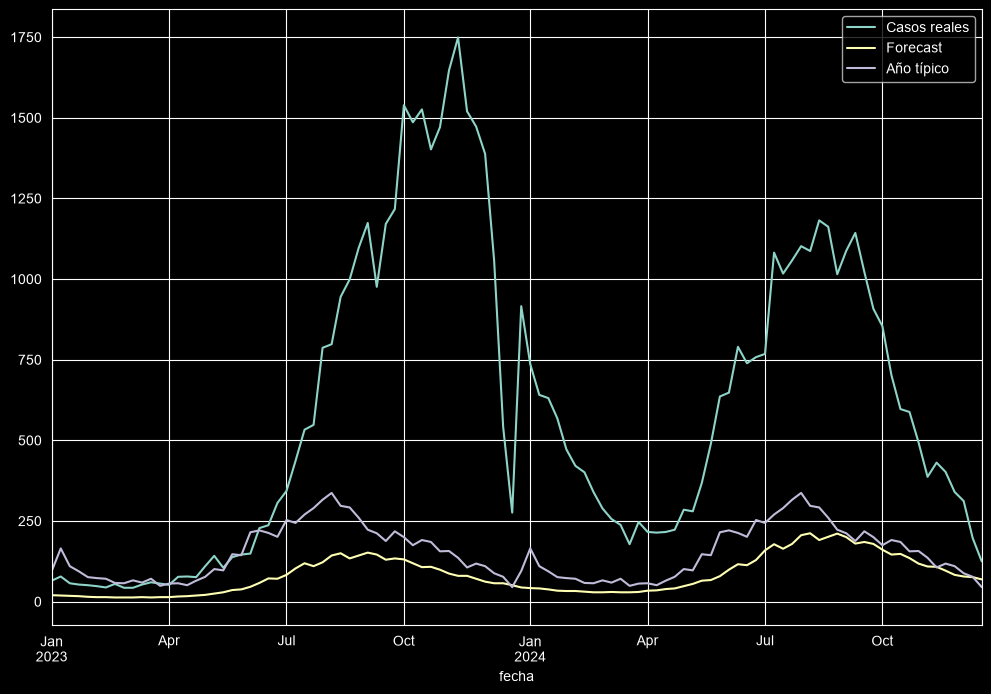

In [81]:
pronostico_2023_2024['Casos reales'] = real_2023_2024
pronostico_2023_2024[['Casos reales', 'Forecast', 'Año típico']].plot(figsize=(12,8))

### Interpretación
- Ni el LSTM a 2 años ni el año típico se acercan a lo que pasó en 2023-2024: los dos se quedan muy por debajo, porque nada en los datos hasta 2022 anunciaba el brote más grande de la serie.
- En cambio, el LSTM pronosticando solo 4 semanas (sección 9.1) sí siguió el brote, porque cada pronóstico usa los casos reales más recientes.
- Conclusión: el modelo sirve para pronosticar las próximas semanas, que es lo que pide el proyecto. Un pronóstico a 2 años solo indica la época del año con más riesgo. En el dashboard, para semanas de 2025-2026 se debe mostrar con un aviso y junto al año típico como referencia.

# 11. Conclusiones
- Entrenamos los dos modelos que pide el proyecto con ventanas de 26 semanas para predecir 4 semanas: una SimpleRNN de base y un LSTM (64, 32, Dropout 0.2, Dense 4).
- El LSTM es el mejor: tiene menos error que el baseline estacional y que la SimpleRNN (tabla de la sección 9.1).
- Lo que más ayudó fue lo que vimos en el EDA: trabajar con log(casos), usar los casos pasados como entrada además del clima, y predecir el cambio respecto a la última semana para poder pronosticar brotes más grandes que los de entrenamiento.
- Limitaciones: el error sube mientras más lejos se predice, el subregistro de fin de año causa errores en diciembre y enero, y solo hay 574 semanas con pocos brotes grandes.
- También pronosticamos 2025 y 2026 repitiendo el pronóstico de 4 semanas. Mantiene la estacionalidad, pero el nivel no es confiable: el error se acumula y el modelo no puede anticipar brotes nuevos. Lo comprobamos pronosticando 2023-2024 con datos hasta 2022, y ni el LSTM ni el año típico anticiparon el brote. El pronóstico útil es el de 4 semanas.
- El modelo final, entrenado con toda la serie, quedó guardado en models/modelo_lstm_casos.h5 con sus escaladores, listo para la app y para el Módulo 3 (ANN).